# Food Demand Forecasting for Supply Chain Planning

This project builds a commercial demand-forecasting pipeline using the Walmart M5 dataset. It processes **27,489,810 product-store-day observations** with RAPIDS, analyzes demand patterns, and compares several regression models.

The final solution aggregates demand into **30 store-department time series** and uses a tuned Prophet model to forecast the next 28 days.

**Business objective:** support inventory replenishment, staffing, and supply planning by estimating future food demand for each store and department.

**Final test performance:** WMAPE **10.31%**, equivalent to a weighted forecast accuracy of approximately **89.69%**.


The notebook has two modeling stages:

- **Detailed Product Forecasting:** compares simple baselines, three cuML regression algorithms, and two GPU XGBoost objectives using product-store-day data.
- **Final Business Forecasting:** compares a weekday baseline with Prophet models using store-department daily demand.


## Project Definition

### Problem Statement

Retailers need reliable demand forecasts to order the right quantity of products, plan staffing, and reduce both stockouts and excess inventory. This project predicts future food demand from historical product, store, calendar, event, SNAP, and price information.

### Dataset

The public [Walmart M5 Forecasting - Accuracy dataset](https://www.kaggle.com/competitions/m5-forecasting-accuracy/data) contains daily sales, calendar events, SNAP indicators, and weekly prices. After filtering the FOODS category and reshaping the sales table, the project processes **27,489,810 rows**.

### Machine Learning

This is a **regression and time-series forecasting** problem because the target is the number of units sold. we used chronological validation and testing so future observations never enter the training period.

### Project Workflow Summary

| Project Stage | Work Completed |
|---|---|
| Data Preparation | Prepared 27,489,810 daily product-store sales records. |
| GPU Data Processing | Used cuDF and CuPy for reshaping, merging, cleaning, and feature engineering. |
| Product-Level Modeling | Trained Linear Regression, Ridge Regression, and Random Forest using cuML. |
| Additional Experiments | Evaluated XGBoost Poisson and XGBoost L1 on detailed product demand. |
| Model Evaluation | Compared models using MAE, RMSE, WMAPE, execution time, and GPU usage. |
| Final Forecasting | Aggregated demand into 30 store-department time series and selected Tuned Prophet. |
| Business Output | Generated 28-day demand forecasts for inventory and supply planning. |

## 1. Environment Setup


In [ ]:
!nvidia-smi


Wed Aug 12 15:11:43 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# Install RAPIDS and the libraries used in this notebook.
!test -d /content/rapidsai-csp-utils || git clone -q https://github.com/rapidsai/rapidsai-csp-utils.git /content/rapidsai-csp-utils
!python /content/rapidsai-csp-utils/colab/pip-install.py
!pip -q install prophet xgboost nvidia-ml-py


Installing RAPIDS remaining 26.02 libraries
Using Python 3.12.13 environment at: /usr
Resolved 180 packages in 2.60s
Prepared 10 packages in 5.44s
Uninstalled 4 packages in 520ms
Installed 10 packages in 181ms
 - bokeh==3.8.2
 + bokeh==3.6.3
 + cugraph-cu12==26.2.0
 + cuxfilter-cu12==26.2.0
 + datashader==0.19.1
 - holoviews==1.23.1
 + holoviews==1.20.2
 + jupyter-server-proxy==4.5.0
 - panel==1.9.3
 + panel==1.7.5
 + pyct==0.6.0
 - shapely==2.1.2
 + shapely==2.0.7
 + simpervisor==1.0.0

        ***********************************************************************
        The pip install of RAPIDS is complete.

        Please do not run any further installation from the conda based installation methods, as they may cause issues!

        Please ensure that you're pulling from the git repo to remain updated with the latest working install scripts.

        Troubleshooting:
            - If there is an installation failure, please check back on RAPIDSAI owned templates/notebooks to see

In [ ]:
import gc
import logging
import os
import threading
import time
import warnings

import cupy as cp
import cudf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb

from cuml.ensemble import RandomForestRegressor
from cuml.linear_model import LinearRegression, Ridge
from prophet import Prophet
from prophet.serialize import model_to_json
from pynvml import (
    nvmlDeviceGetHandleByIndex,
    nvmlDeviceGetMemoryInfo,
    nvmlDeviceGetUtilizationRates,
    nvmlInit,
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Reduce noisy logs from Prophet and CmdStanPy.
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
logging.getLogger("prophet").setLevel(logging.WARNING)
warnings.filterwarnings("ignore")

# Initialize NVIDIA's monitoring interface once for this Colab session.
nvmlInit()
GPU_HANDLE = nvmlDeviceGetHandleByIndex(0)


def current_gpu_snapshot():
    utilization = nvmlDeviceGetUtilizationRates(GPU_HANDLE)
    memory = nvmlDeviceGetMemoryInfo(GPU_HANDLE)
    return {
        "utilization_percent": float(utilization.gpu),
        "memory_used_mb": float(memory.used / 1024**2),
        "memory_total_mb": float(memory.total / 1024**2),
    }


def start_gpu_timer():
    cp.cuda.Stream.null.synchronize()
    return time.perf_counter()


def show_gpu_time(start_time, task_name):
    cp.cuda.Stream.null.synchronize()
    elapsed_seconds = time.perf_counter() - start_time
    snapshot = current_gpu_snapshot()
    print(f"GPU cell time - {task_name}: {elapsed_seconds:.2f} seconds")
    print(
        "GPU snapshot - "
        f"utilization: {snapshot['utilization_percent']:.0f}%, "
        f"memory: {snapshot['memory_used_mb']:.0f} / "
        f"{snapshot['memory_total_mb']:.0f} MB"
    )


def start_timer():
    return time.perf_counter()


def show_time(start_time, task_name):
    elapsed_seconds = time.perf_counter() - start_time
    print(f"Execution time - {task_name}: {elapsed_seconds:.2f} seconds")


def to_cupy(values):
    if hasattr(values, "to_cupy"):
        return values.to_cupy()
    return cp.asarray(values)


class GPUPerformanceMonitor:
    # Sample GPU utilization and memory while a model is running.

    def __init__(self, sample_interval=0.20):
        self.sample_interval = sample_interval
        self.utilization_samples = []
        self.memory_samples_mb = []
        self._stop_event = threading.Event()
        self._thread = None

    def _take_sample(self):
        try:
            snapshot = current_gpu_snapshot()
            self.utilization_samples.append(snapshot["utilization_percent"])
            self.memory_samples_mb.append(snapshot["memory_used_mb"])
        except Exception:
            pass

    def _sample_loop(self):
        while not self._stop_event.wait(self.sample_interval):
            self._take_sample()

    def start(self):
        self._take_sample()
        self._thread = threading.Thread(target=self._sample_loop, daemon=True)
        self._thread.start()

    def stop(self):
        self._stop_event.set()
        if self._thread is not None:
            self._thread.join()
        self._take_sample()

        return {
            "Average GPU Utilization (%)": float(np.mean(self.utilization_samples)),
            "Maximum GPU Utilization (%)": float(np.max(self.utilization_samples)),
            "Peak GPU Memory (MB)": float(np.max(self.memory_samples_mb)),
        }


gpu_snapshot = current_gpu_snapshot()
print("cuDF version:", cudf.__version__)
print("XGBoost version:", xgb.__version__)
print("GPU memory:", round(gpu_snapshot["memory_total_mb"]), "MB")


cuDF version: 26.02.01
XGBoost version: 3.3.0
GPU memory: 15360 MB


In [ ]:
from google.colab import drive
# Mount Google Drive and set up directory paths for M5 dataset and checkpoints
drive.mount("/content/drive")

DATA_ZIP_PATH = "/content/drive/MyDrive/M5_Project/m5-forecasting-accuracy.zip"
EXTRACTED_DATA_PATH = "/content/m5_data"
OUTPUT_PATH = "/content/drive/MyDrive/M5_Project/checkpoints"

os.makedirs(EXTRACTED_DATA_PATH, exist_ok=True)
os.makedirs(OUTPUT_PATH, exist_ok=True)
# Unzip dataset
!unzip -qo "$DATA_ZIP_PATH" -d "$EXTRACTED_DATA_PATH"


Mounted at /content/drive


## 2. Load the Source Data

The project uses three M5 files:

- `sales_train_validation.csv`: daily product sales.
- `calendar.csv`: dates, events, and SNAP indicators.
- `sell_prices.csv`: weekly product prices by store.

The shape of each table is displayed to verify the number of rows and columns after loading.

In [ ]:
gpu_start = start_gpu_timer()

raw_sales_gpu = cudf.read_csv(f"{EXTRACTED_DATA_PATH}/sales_train_validation.csv")
raw_calendar_gpu = cudf.read_csv(f"{EXTRACTED_DATA_PATH}/calendar.csv")
raw_prices_gpu = cudf.read_csv(f"{EXTRACTED_DATA_PATH}/sell_prices.csv")

print("Sales table:", raw_sales_gpu.shape)
print("Calendar table:", raw_calendar_gpu.shape)
print("Price table:", raw_prices_gpu.shape)

show_gpu_time(gpu_start, "load source files")


Sales table: (30490, 1919)
Calendar table: (1969, 14)
Price table: (6841121, 4)
GPU cell time - load source files: 1.36 seconds
GPU snapshot - utilization: 18%, memory: 1334 / 15360 MB


A **sample** of each source table is displayed.

In [ ]:
gpu_start = start_gpu_timer()

print("Sales sample:")
display(raw_sales_gpu.head())

print("Calendar sample:")
display(raw_calendar_gpu.head())

print("Prices sample:")
display(raw_prices_gpu.head())

show_gpu_time(gpu_start, "display source-data samples")


Sales sample:


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,3,0,1,1,1,3,0,1,1
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,2,1,1,1,0,1,1,1
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,5,4,1,0,1,3,7,2
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,1,0,1,1,2,2,2,4


Calendar sample:


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,<NA>,<NA>,<NA>,<NA>,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,<NA>,<NA>,<NA>,<NA>,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,<NA>,<NA>,<NA>,<NA>,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,<NA>,<NA>,<NA>,<NA>,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,<NA>,<NA>,<NA>,<NA>,1,0,1


Prices sample:


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


GPU cell time - display source-data samples: 2.32 seconds
GPU snapshot - utilization: 8%, memory: 1334 / 15360 MB


The sales data is filtered to keep only food products, and the daily sales columns are identified. Basic quality checks are then performed to examine missing values, duplicates, zero sales, and the expected number of rows after reshaping.

In [ ]:
gpu_start = start_gpu_timer()
# Filter category for FOODS
food_sales_wide_gpu = raw_sales_gpu[raw_sales_gpu["cat_id"] == "FOODS"].copy()
# Collect daily sales columns
sales_day_columns = [
    column_name
    for column_name in food_sales_wide_gpu.columns
    if column_name.startswith("d_")
]

# Data sanity and quality check
expected_long_rows = len(food_sales_wide_gpu) * len(sales_day_columns)
missing_sales_count = int(food_sales_wide_gpu[sales_day_columns].isnull().sum().sum())
duplicate_series_count = int(food_sales_wide_gpu["id"].duplicated().sum())
zero_sales_count = int((food_sales_wide_gpu[sales_day_columns] == 0).sum().sum())
zero_sales_percentage = zero_sales_count / expected_long_rows * 100

print("FOODS table before reshaping:", food_sales_wide_gpu.shape)
print("Expected long-format rows:", f"{expected_long_rows:,}")
print("Products:", food_sales_wide_gpu["item_id"].nunique())
print("Stores:", food_sales_wide_gpu["store_id"].nunique())
print("Departments:", food_sales_wide_gpu["dept_id"].nunique())
print("Missing sales values:", missing_sales_count)
print("Duplicate product-store series:", duplicate_series_count)
print("Zero-sales percentage:", round(zero_sales_percentage, 2), "%")

show_gpu_time(gpu_start, "inspect FOODS sales")


FOODS table before reshaping: (14370, 1919)
Expected long-format rows: 27,489,810
Products: 1437
Stores: 10
Departments: 3
Missing sales values: 0
Duplicate product-store series: 0
Zero-sales percentage: 62.02 %
GPU cell time - inspect FOODS sales: 3.42 seconds
GPU snapshot - utilization: 11%, memory: 1552 / 15360 MB


### FOODS Data Overview

- **Data scope:** 1,437 products, 10 stores, 3 departments, and 1,913 days.
- **Zero-sales rate:** approximately 62% of product-store-day observations have zero sales.
- **Insight:** individual product demand is intermittent, with frequent zero-sales days and occasional demand spikes.


## 3. Encode Categories and Reshape Sales


String identifiers are converted into compact numeric codes to reduce GPU memory use. Mapping tables preserve the original product, department, store, and state names for readable reports and saved predictions.

In [ ]:
gpu_start = start_gpu_timer()

# Optimize memory usage by converting daily sales to int16
# And encoding text identifiers into compact integer codes (int8/int16)
food_sales_wide_gpu = food_sales_wide_gpu.astype(
    {column_name: "int16" for column_name in sales_day_columns}
)

food_sales_wide_gpu["product_code"] = (
    food_sales_wide_gpu["item_id"].astype("category").cat.codes.astype("int16")
)
food_sales_wide_gpu["department_code"] = (
    food_sales_wide_gpu["dept_id"].astype("category").cat.codes.astype("int8")
)
food_sales_wide_gpu["store_code"] = (
    food_sales_wide_gpu["store_id"].astype("category").cat.codes.astype("int8")
)
food_sales_wide_gpu["state_code"] = (
    food_sales_wide_gpu["state_id"].astype("category").cat.codes.astype("int8")
)
# Create mapping table between original product IDs and encoded integer codes
product_mapping_gpu = (
    food_sales_wide_gpu[["item_id", "product_code"]]
    .drop_duplicates()
    .sort_values("product_code")
    .reset_index(drop=True)
)
# Create mapping table between original department IDs and encoded integer codes
department_mapping_gpu = (
    food_sales_wide_gpu[["dept_id", "department_code"]]
    .drop_duplicates()
    .sort_values("department_code")
    .reset_index(drop=True)
)
# Create mapping table between original store IDs and encoded integer codes
store_mapping_gpu = (
    food_sales_wide_gpu[["store_id", "store_code"]]
    .drop_duplicates()
    .sort_values("store_code")
    .reset_index(drop=True)
)
# Create mapping table between original state IDs and encoded integer codes
state_mapping_gpu = (
    food_sales_wide_gpu[["state_id", "state_code"]]
    .drop_duplicates()
    .sort_values("state_code")
    .reset_index(drop=True)
)

identifier_columns = ["product_code", "department_code", "store_code", "state_code"]
encoded_food_sales_gpu = food_sales_wide_gpu[identifier_columns + sales_day_columns].copy()

print("Encoded products:", len(product_mapping_gpu))
print("Encoded departments:", len(department_mapping_gpu))
print("Encoded stores:", len(store_mapping_gpu))
print("Encoded states:", len(state_mapping_gpu))

show_gpu_time(gpu_start, "encode categorical identifiers")


Encoded products: 1437
Encoded departments: 3
Encoded stores: 10
Encoded states: 3
GPU cell time - encode categorical identifiers: 0.65 seconds
GPU snapshot - utilization: 7%, memory: 1404 / 15360 MB


### Reshape Sales Data into Long Format

The sales dataset is currently stored in wide format, where each day is represented by a separate column. In this step, the `melt()` function is used to convert the dataset from wide format into long format.

The `id_vars` parameter keeps the product, department, store, and state identifiers unchanged, while `value_vars` specifies the daily sales columns that will be transformed. The original day-column names are stored in the new `day_id` column, and their sales values are stored in the new `units_sold` column.

`melt()` was used because long format creates one row for each product, store, and day. This structure is easier to merge with calendar and price data, analyze as a time series, and use for machine learning. Numeric day identifiers are also extracted to simplify future joins and reduce memory usage.

Finally, unnecessary tables are removed from memory, and the GPU execution time is displayed.


In [ ]:
gpu_start = start_gpu_timer()

food_sales_long_gpu = encoded_food_sales_gpu.melt(
    id_vars=identifier_columns,
    value_vars=sales_day_columns,
    var_name="day_id",
    value_name="units_sold"
)
food_sales_long_gpu["day_id"] = (
    food_sales_long_gpu["day_id"].str.slice(start=2).astype("int16")
)

del raw_sales_gpu, food_sales_wide_gpu, encoded_food_sales_gpu
gc.collect()

print("Long sales table:", food_sales_long_gpu.shape)
display(food_sales_long_gpu.head())

show_gpu_time(gpu_start, "reshape sales to long format")


Long sales table: (27489810, 6)


,product_code,department_code,store_code,state_code,day_id,units_sold
0,0,0,0,0,1,3
1,1,0,0,0,1,0
2,2,0,0,0,1,0
3,3,0,0,0,1,0
4,4,0,0,0,1,3


GPU cell time - reshape sales to long format: 0.66 seconds
GPU snapshot - utilization: 47%, memory: 1108 / 15360 MB


The GPU reshape creates **27,489,810** product-store-day rows.


## 4. Prepare Calendar and Price Features

Calendar events, dates, SNAP indicators, and weekly prices are converted into compact features that can be merged with daily sales.
SNAP is a U.S. food-assistance program that may influence customer demand.

In [ ]:
gpu_start = start_gpu_timer()

calendar_gpu = raw_calendar_gpu.copy()
calendar_gpu["day_id"] = calendar_gpu["d"].str.slice(start=2).astype("int16")
calendar_gpu["date"] = cudf.to_datetime(calendar_gpu["date"], format="%Y-%m-%d")
calendar_gpu["week_id"] = calendar_gpu["wm_yr_wk"].astype("int32")
calendar_gpu["calendar_weekday"] = calendar_gpu["wday"].astype("int8")
calendar_gpu["month"] = calendar_gpu["month"].astype("int8")
calendar_gpu["year"] = calendar_gpu["year"].astype("int16")

for snap_column in ["snap_CA", "snap_TX", "snap_WI"]:
    calendar_gpu[snap_column] = calendar_gpu[snap_column].astype("int8")

event_code_names = {
    "event_name_1": "primary_event_code",
    "event_type_1": "primary_event_type_code",
    "event_name_2": "secondary_event_code",
    "event_type_2": "secondary_event_type_code",
}
event_mapping_tables = {}

for original_column, clear_code_name in event_code_names.items():
    calendar_gpu[original_column] = calendar_gpu[original_column].fillna("No Event")
    calendar_gpu[clear_code_name] = (
        calendar_gpu[original_column].astype("category").cat.codes.astype("int8")
    )
    event_mapping_tables[clear_code_name] = (
        calendar_gpu[[original_column, clear_code_name]]
        .drop_duplicates()
        .sort_values(clear_code_name)
        .reset_index(drop=True)
    )

primary_event_mapping = event_mapping_tables["primary_event_code"].to_pandas()
NO_EVENT_CODE = int(
    primary_event_mapping.loc[
        primary_event_mapping["event_name_1"] == "No Event",
        "primary_event_code",
    ].iloc[0]
)

calendar_event_dates = (
    calendar_gpu[["date", "primary_event_code"]]
    .drop_duplicates()
    .to_pandas()
)
calendar_event_dates["date"] = pd.to_datetime(calendar_event_dates["date"])

calendar_features_gpu = calendar_gpu[
    [
        "day_id", "date", "week_id", "calendar_weekday", "month", "year",
        "primary_event_code", "primary_event_type_code",
        "secondary_event_code", "secondary_event_type_code",
        "snap_CA", "snap_TX", "snap_WI",
    ]
].copy()

print("Prepared calendar table:", calendar_features_gpu.shape)
print("No-event code:", NO_EVENT_CODE)

del raw_calendar_gpu, calendar_gpu
gc.collect()

show_gpu_time(gpu_start, "prepare calendar and event features")


Prepared calendar table: (1969, 13)
No-event code: 19
GPU cell time - prepare calendar and event features: 0.31 seconds
GPU snapshot - utilization: 1%, memory: 1106 / 15360 MB


The weekly price data is prepared by encoding products and stores, selecting the required columns, and optimizing data types. Duplicate and missing prices are also checked before merging the prices with daily sales.

In [ ]:
gpu_start = start_gpu_timer()

food_prices_gpu = raw_prices_gpu.rename(
    columns={"wm_yr_wk": "week_id", "sell_price": "sale_price"}
)
food_prices_gpu["week_id"] = food_prices_gpu["week_id"].astype("int32")
food_prices_gpu["sale_price"] = food_prices_gpu["sale_price"].astype("float32")

food_prices_gpu = food_prices_gpu.merge(product_mapping_gpu, on="item_id", how="inner")
food_prices_gpu = food_prices_gpu.merge(store_mapping_gpu, on="store_id", how="inner")
food_prices_gpu = food_prices_gpu[
    ["product_code", "store_code", "week_id", "sale_price"]
].copy()
food_prices_gpu["product_code"] = food_prices_gpu["product_code"].astype("int16")
food_prices_gpu["store_code"] = food_prices_gpu["store_code"].astype("int8")

duplicate_price_rows = int(
    food_prices_gpu.duplicated(
        subset=["product_code", "store_code", "week_id"]
    ).sum()
)

print("FOODS price table:", food_prices_gpu.shape)
print("Duplicate price rows:", duplicate_price_rows)
print("Missing prices in price file:", int(food_prices_gpu["sale_price"].isnull().sum()))

del raw_prices_gpu
gc.collect()

show_gpu_time(gpu_start, "prepare food prices")


FOODS price table: (3181789, 4)
Duplicate price rows: 0
Missing prices in price file: 0
GPU cell time - prepare food prices: 0.24 seconds
GPU snapshot - utilization: 45%, memory: 872 / 15360 MB


## 5. Merge the Modeling Data

The long sales table is joined with calendar and weekly price features to create the complete 27.5-million-row modeling dataset.


In [ ]:
gpu_start = start_gpu_timer()

rows_before_merge = len(food_sales_long_gpu)

modeling_data_gpu = food_sales_long_gpu.merge(
    calendar_features_gpu,
    on="day_id",
    how="left"
)
modeling_data_gpu = modeling_data_gpu.merge(
    food_prices_gpu,
    on=["product_code", "store_code", "week_id"],
    how="left"
)

print("Rows before merging:", f"{rows_before_merge:,}")
print("Rows after merging:", f"{len(modeling_data_gpu):,}")
print("Merged table:", modeling_data_gpu.shape)
print("Missing calendar dates:", int(modeling_data_gpu["date"].isnull().sum()))

del food_sales_long_gpu, calendar_features_gpu, food_prices_gpu
gc.collect()

show_gpu_time(gpu_start, "merge sales, calendar, and prices")


Rows before merging: 27,489,810
Rows after merging: 27,489,810
Merged table: (27489810, 19)
Missing calendar dates: 0
GPU cell time - merge sales, calendar, and prices: 0.39 seconds
GPU snapshot - utilization: 48%, memory: 1562 / 15360 MB


Missing prices are examined to confirm that they occur only when no units were sold. They are replaced with zero, while a separate availability indicator allows the models to distinguish unavailable prices from valid values.

In [ ]:
gpu_start = start_gpu_timer()

missing_price_count = int(modeling_data_gpu["sale_price"].isnull().sum())
missing_price_percentage = missing_price_count / len(modeling_data_gpu) * 100
missing_price_with_sales = int(
    (
        modeling_data_gpu["sale_price"].isnull()
        & (modeling_data_gpu["units_sold"] > 0)
    ).sum()
)

modeling_data_gpu["price_is_available"] = (
    modeling_data_gpu["sale_price"].notnull().astype("int8")
)
modeling_data_gpu["sale_price"] = (
    modeling_data_gpu["sale_price"].fillna(0).astype("float32")
)

remaining_missing = modeling_data_gpu.isnull().sum()

print("Missing prices before treatment:", f"{missing_price_count:,}")
print("Missing-price percentage:", round(missing_price_percentage, 2), "%")
print("Missing-price rows with positive sales:", missing_price_with_sales)
print("Columns still containing missing values:")
print(remaining_missing[remaining_missing > 0])
print("Clean modeling table:", modeling_data_gpu.shape)

show_gpu_time(gpu_start, "treat missing prices")


Missing prices before treatment: 6,093,857
Missing-price percentage: 22.17 %
Missing-price rows with positive sales: 0
Columns still containing missing values:
Series([], dtype: int64)
Clean modeling table: (27489810, 20)
GPU cell time - treat missing prices: 0.17 seconds
GPU snapshot - utilization: 48%, memory: 1588 / 15360 MB


All missing-price rows had zero sales. A missing price is therefore treated as product unavailability: `sale_price` is filled with zero, while `price_is_available` preserves the original availability information. No sales rows are deleted.

## 6. Exploratory Data Analysis

The analysis summarizes demand over time and compares departments, stores, weekdays, events, and SNAP availability.


### Question: How did the average daily demand for food products change over time?

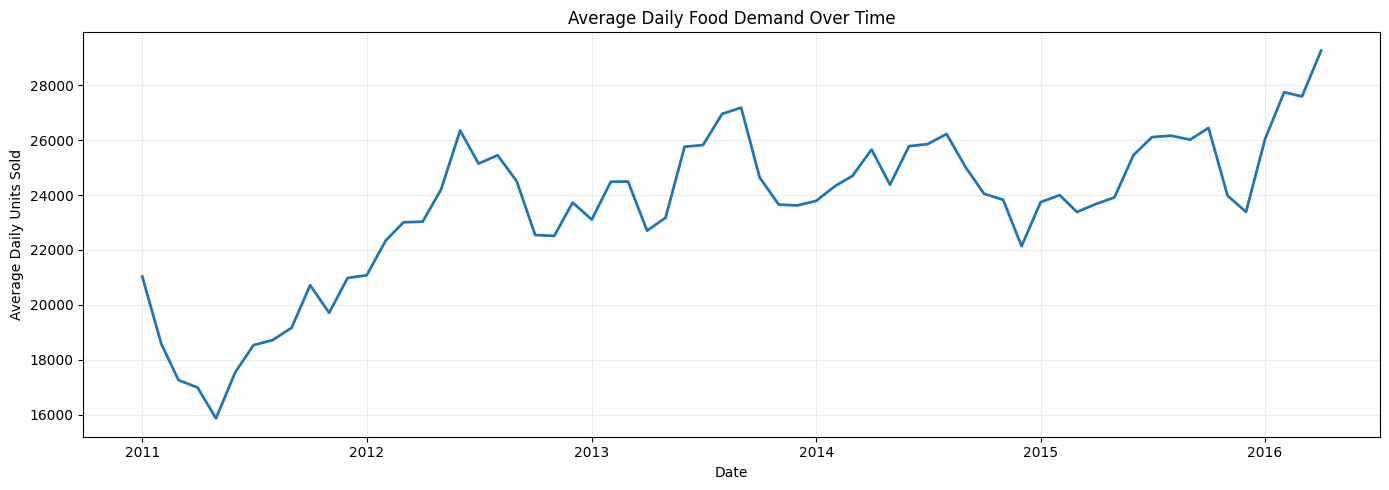

,date,average_daily_units
0,2011-01-01,21036.666667
1,2011-02-01,18580.357143
2,2011-03-01,17255.290323
3,2011-04-01,16985.600000
4,2011-05-01,15863.000000


GPU cell time - aggregate the monthly demand trend: 0.41 seconds
GPU snapshot - utilization: 0%, memory: 1602 / 15360 MB


In [ ]:
gpu_start = start_gpu_timer()

daily_demand_gpu = (
    modeling_data_gpu.groupby("date")["units_sold"]
    .sum()
    .reset_index()
    .sort_values("date")
)
daily_demand = daily_demand_gpu.to_pandas()
daily_demand["date"] = pd.to_datetime(daily_demand["date"])

monthly_demand = (
    daily_demand.set_index("date")["units_sold"]
    .resample("MS")
    .mean()
    .reset_index(name="average_daily_units")
)

plt.figure(figsize=(14, 5))
plt.plot(monthly_demand["date"], monthly_demand["average_daily_units"], linewidth=2)
plt.title("Average Daily Food Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Average Daily Units Sold")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

display(monthly_demand.head())
show_gpu_time(gpu_start, "aggregate the monthly demand trend")


Average daily food demand shows an overall upward trend from 2011 to 2016, despite recurring fluctuations. Demand reached its highest level near the end of the observed period.

### Question: Which food department has the highest average daily demand?

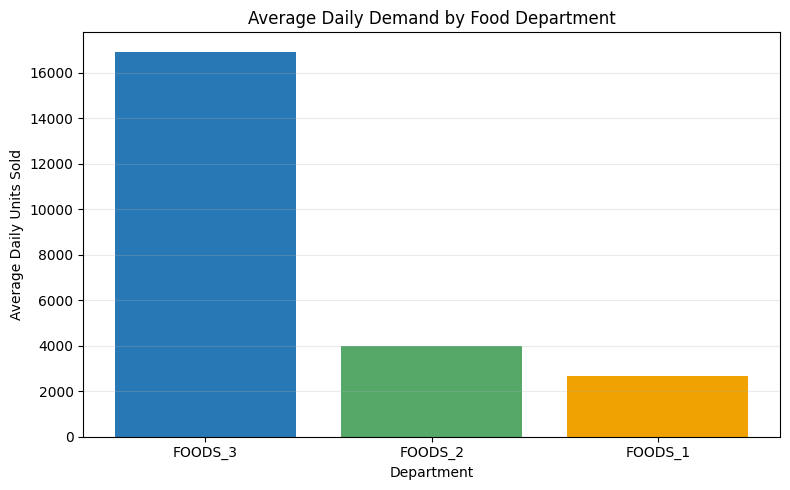

,department_code,average_daily_units,dept_id
0,2,16922.151594,FOODS_3
1,1,3988.406691,FOODS_2
2,0,2659.718244,FOODS_1


GPU cell time - compare departments: 0.20 seconds
GPU snapshot - utilization: 15%, memory: 1604 / 15360 MB


In [ ]:
gpu_start = start_gpu_timer()

department_daily_gpu = (
    modeling_data_gpu.groupby(["date", "department_code"])["units_sold"]
    .sum()
    .reset_index()
)
department_summary_gpu = (
    department_daily_gpu.groupby("department_code")["units_sold"]
    .mean()
    .reset_index(name="average_daily_units")
    .merge(department_mapping_gpu, on="department_code", how="left")
)
department_summary = (
    department_summary_gpu.to_pandas()
    .sort_values("average_daily_units", ascending=False)
)

plt.figure(figsize=(8, 5))
plt.bar(
    department_summary["dept_id"],
    department_summary["average_daily_units"],
    color=["#2878B5", "#55A868", "#F0A202"],
)
plt.title("Average Daily Demand by Food Department")
plt.xlabel("Department")
plt.ylabel("Average Daily Units Sold")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

display(department_summary)
show_gpu_time(gpu_start, "compare departments")


FOODS_3 has the highest average daily demand at approximately 16,922 units, far exceeding FOODS_2 and FOODS_1.

### Question: Which store has the highest average daily food demand?

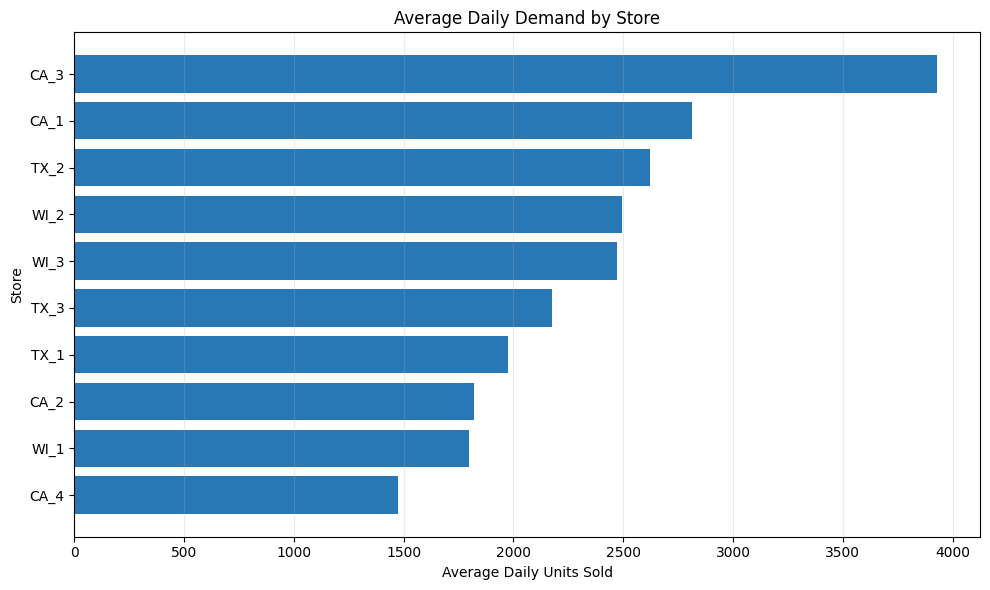

,store_code,average_daily_units,store_id
3,3,1473.823837,CA_4
8,7,1797.361213,WI_1
6,1,1819.267642,CA_2
0,4,1975.017773,TX_1
1,6,2176.209096,TX_3
4,9,2472.911657,WI_3
9,8,2492.516466,WI_2
2,5,2621.601673,TX_2
7,0,2812.769472,CA_1
5,2,3928.797700,CA_3


GPU cell time - compare stores: 0.21 seconds
GPU snapshot - utilization: 15%, memory: 1604 / 15360 MB


In [ ]:
gpu_start = start_gpu_timer()

store_daily_gpu = (
    modeling_data_gpu.groupby(["date", "store_code"])["units_sold"]
    .sum()
    .reset_index()
)
store_summary_gpu = (
    store_daily_gpu.groupby("store_code")["units_sold"]
    .mean()
    .reset_index(name="average_daily_units")
    .merge(store_mapping_gpu, on="store_code", how="left")
)
store_summary = (
    store_summary_gpu.to_pandas()
    .sort_values("average_daily_units", ascending=True)
)

plt.figure(figsize=(10, 6))
plt.barh(store_summary["store_id"], store_summary["average_daily_units"], color="#2878B5")
plt.title("Average Daily Demand by Store")
plt.xlabel("Average Daily Units Sold")
plt.ylabel("Store")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

display(store_summary)
show_gpu_time(gpu_start, "compare stores")


CA_3 has the highest average daily demand at approximately 3,929 units, while CA_4 records the lowest at approximately 1,474 units.

### Question: Which day of the week has the highest average daily food demand?

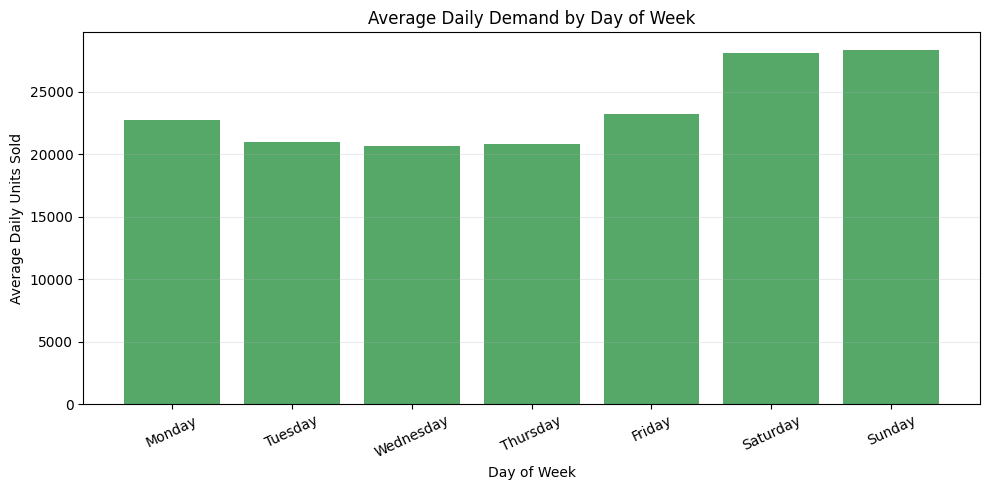

,day_of_week,day_name,average_daily_units
0,0,Monday,22735.402930
1,1,Tuesday,21014.058608
2,2,Wednesday,20700.274725
3,3,Thursday,20819.956044
4,4,Friday,23264.146520
5,5,Saturday,28077.200730
6,6,Sunday,28346.890511


In [ ]:
day_name_lookup = {
    0: "Monday", 1: "Tuesday", 2: "Wednesday", 3: "Thursday",
    4: "Friday", 5: "Saturday", 6: "Sunday",
}

daily_demand["day_of_week"] = daily_demand["date"].dt.dayofweek
daily_demand["day_name"] = daily_demand["day_of_week"].map(day_name_lookup)
weekday_summary = (
    daily_demand.groupby(["day_of_week", "day_name"])["units_sold"]
    .mean()
    .reset_index(name="average_daily_units")
    .sort_values("day_of_week")
)

plt.figure(figsize=(10, 5))
plt.bar(weekday_summary["day_name"], weekday_summary["average_daily_units"], color="#55A868")
plt.title("Average Daily Demand by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Daily Units Sold")
plt.xticks(rotation=25)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

display(weekday_summary)


Sunday has the highest average daily demand at approximately 28,347 units, followed closely by Saturday, while Wednesday records the lowest demand.

### Question: Is average daily food demand higher on event days than on normal days?

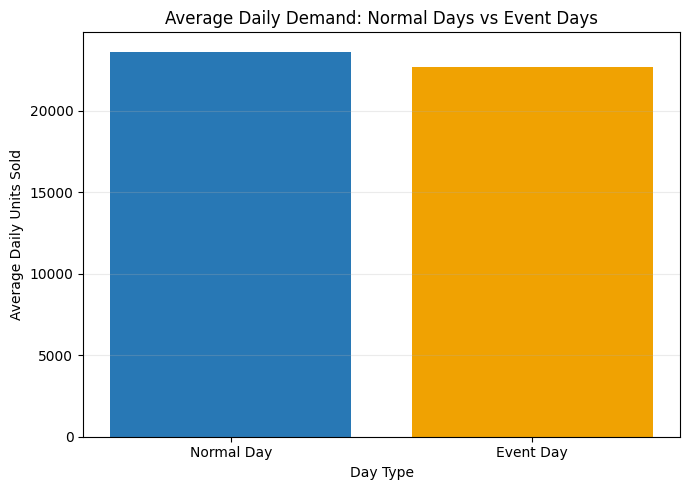

,is_event_day,average_daily_units,day_type
0,0,23645.030699,Normal Day
1,1,22716.428571,Event Day


Average demand change on event days: -3.93 %
GPU cell time - compare normal and event days: 0.16 seconds
GPU snapshot - utilization: 0%, memory: 1604 / 15360 MB


In [ ]:
gpu_start = start_gpu_timer()

event_daily_gpu = (
    modeling_data_gpu.groupby(["date", "primary_event_code"])["units_sold"]
    .sum()
    .reset_index()
)
event_daily_gpu["is_event_day"] = (
    event_daily_gpu["primary_event_code"] != NO_EVENT_CODE
).astype("int8")
event_summary_gpu = (
    event_daily_gpu.groupby("is_event_day")["units_sold"]
    .mean()
    .reset_index(name="average_daily_units")
)
event_summary = event_summary_gpu.to_pandas()
event_summary["day_type"] = event_summary["is_event_day"].map(
    {0: "Normal Day", 1: "Event Day"}
)

normal_event_level = event_summary.loc[
    event_summary["is_event_day"] == 0, "average_daily_units"
].iloc[0]
special_event_level = event_summary.loc[
    event_summary["is_event_day"] == 1, "average_daily_units"
].iloc[0]
event_change_percentage = (
    (special_event_level - normal_event_level) / normal_event_level * 100
)

plt.figure(figsize=(7, 5))
plt.bar(event_summary["day_type"], event_summary["average_daily_units"], color=["#2878B5", "#F0A202"])
plt.title("Average Daily Demand: Normal Days vs Event Days")
plt.xlabel("Day Type")
plt.ylabel("Average Daily Units Sold")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

display(event_summary)
print("Average demand change on event days:", round(event_change_percentage, 2), "%")
show_gpu_time(gpu_start, "compare normal and event days")


No. Average demand on event days is approximately 3.93% lower than on normal days, indicating that events do not always increase food demand.

### Question: Is average daily food demand higher when SNAP benefits are active?

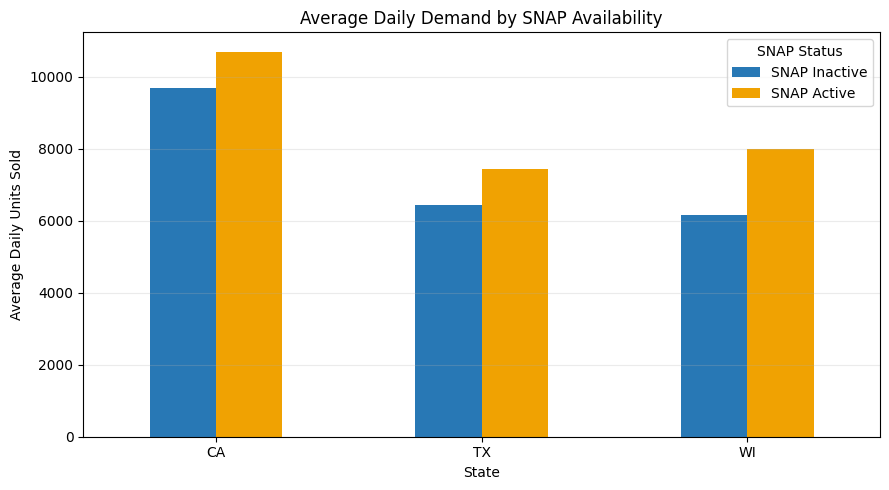

,state_id,snap_active,average_daily_units,snap_status
0,CA,0,9705.484022,SNAP Inactive
1,CA,1,10705.025397,SNAP Active
2,TX,0,6441.684334,SNAP Inactive
3,TX,1,7447.206349,SNAP Active
4,WI,0,6156.462977,SNAP Inactive
5,WI,1,7997.577778,SNAP Active


GPU cell time - analyze SNAP demand: 0.24 seconds
GPU snapshot - utilization: 19%, memory: 1606 / 15360 MB


In [ ]:
gpu_start = start_gpu_timer()

snap_daily_gpu = (
    modeling_data_gpu.groupby(
        ["date", "state_code", "snap_CA", "snap_TX", "snap_WI"]
    )["units_sold"]
    .sum()
    .reset_index()
)
snap_daily = snap_daily_gpu.to_pandas().merge(
    state_mapping_gpu.to_pandas(), on="state_code", how="left"
)
snap_daily["snap_active"] = np.select(
    [
        snap_daily["state_id"] == "CA",
        snap_daily["state_id"] == "TX",
        snap_daily["state_id"] == "WI",
    ],
    [snap_daily["snap_CA"], snap_daily["snap_TX"], snap_daily["snap_WI"]],
).astype("int8")
snap_summary = (
    snap_daily.groupby(["state_id", "snap_active"])["units_sold"]
    .mean()
    .reset_index(name="average_daily_units")
)
snap_summary["snap_status"] = snap_summary["snap_active"].map(
    {0: "SNAP Inactive", 1: "SNAP Active"}
)
snap_chart = snap_summary.pivot(
    index="state_id", columns="snap_status", values="average_daily_units"
)[["SNAP Inactive", "SNAP Active"]]

snap_chart.plot(kind="bar", figsize=(9, 5), color=["#2878B5", "#F0A202"])
plt.title("Average Daily Demand by SNAP Availability")
plt.xlabel("State")
plt.ylabel("Average Daily Units Sold")
plt.xticks(rotation=0)
plt.legend(title="SNAP Status")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

display(snap_summary)
show_gpu_time(gpu_start, "analyze SNAP demand")


Yes. Average daily demand is higher on SNAP-active days in all three states, with the largest increase appearing in Wisconsin.

### Main EDA Findings

- Demand shows a long-term upward trend and recurring seasonality.
- `FOODS_3` has the highest department-level demand.
- Store demand differs substantially, with `CA_3` historically highest.
- Weekend demand is higher than midweek demand.
- Events do not have one uniform effect, so individual event dates are retained.
- SNAP-active days have higher average demand in all three states.


## 7. Detailed Product-Demand

This stage predicts daily units sold for each product-store pair. It demonstrates GPU regression on detailed retail data before demand is aggregated for the final business forecast.

### 7.1 Create Historical Demand Features


In [ ]:
gpu_start = start_gpu_timer()

modeling_data_gpu = modeling_data_gpu.sort_values(
    ["product_code", "store_code", "day_id"]
).reset_index(drop=True)

product_group_columns = ["product_code", "store_code"]

for lag_days in [1, 7, 14, 28]:
    feature_name = f"units_lag_{lag_days}"
    modeling_data_gpu[feature_name] = (
        modeling_data_gpu.groupby(product_group_columns)["units_sold"]
        .shift(lag_days)
        .fillna(0)
        .astype("int16")
    )

print("Created sales lags: 1, 7, 14, and 28 days")
show_gpu_time(gpu_start, "create sales lag features")


Created sales lags: 1, 7, 14, and 28 days
GPU cell time - create sales lag features: 1.32 seconds
GPU snapshot - utilization: 97%, memory: 1828 / 15360 MB


Rolling averages and variability are calculated from previous sales to capture short-term and long-term demand patterns for each product-store pair.

In [ ]:
gpu_start = start_gpu_timer()

for window_days in [7, 14, 28]:
    feature_name = f"units_rolling_mean_{window_days}"
    rolling_average = (
        modeling_data_gpu.groupby(product_group_columns, sort=False)["units_lag_1"]
        .rolling(window=window_days, min_periods=1)
        .mean()
        .reset_index(drop=True)
    )
    modeling_data_gpu[feature_name] = rolling_average.fillna(0).astype("float32")

rolling_std = (
    modeling_data_gpu.groupby(product_group_columns, sort=False)["units_lag_1"]
    .rolling(window=28, min_periods=1)
    .std()
    .reset_index(drop=True)
)
modeling_data_gpu["units_rolling_std_28"] = rolling_std.fillna(0).astype("float32")
modeling_data_gpu["demand_trend_7_vs_28"] = (
    modeling_data_gpu["units_rolling_mean_7"]
    - modeling_data_gpu["units_rolling_mean_28"]
).astype("float32")

print("Created rolling averages, variability, and short-term trend")
show_gpu_time(gpu_start, "create rolling demand features")


Created rolling averages, variability, and short-term trend
GPU cell time - create rolling demand features: 0.96 seconds
GPU snapshot - utilization: 99%, memory: 2778 / 15360 MB


Weekday, weekend, and weekly price-change features are created to help the models capture calendar patterns and the effect of price changes on product demand.

In [ ]:
gpu_start = start_gpu_timer()

modeling_data_gpu["day_of_week"] = modeling_data_gpu["date"].dt.weekday.astype("int8")
modeling_data_gpu["is_weekend"] = (
    modeling_data_gpu["day_of_week"].isin([5, 6]).astype("int8")
)

modeling_data_gpu["price_lag_7"] = (
    modeling_data_gpu.groupby(product_group_columns)["sale_price"]
    .shift(7)
    .fillna(0)
    .astype("float32")
)
modeling_data_gpu["price_difference_7"] = (
    modeling_data_gpu["sale_price"] - modeling_data_gpu["price_lag_7"]
).astype("float32")

safe_previous_price = modeling_data_gpu["price_lag_7"].where(
    modeling_data_gpu["price_lag_7"] > 0
)
modeling_data_gpu["price_change_rate_7"] = (
    (
        modeling_data_gpu["sale_price"] - modeling_data_gpu["price_lag_7"]
    ) / safe_previous_price
).fillna(0).astype("float32")

print("Created weekday and price-change features")
show_gpu_time(gpu_start, "create calendar and price features")


Created weekday and price-change features
GPU cell time - create calendar and price features: 0.32 seconds
GPU snapshot - utilization: 96%, memory: 3318 / 15360 MB


### 7.2 Define Features and Chronological Splits


The input features include product and store information, calendar events, SNAP indicators, prices, and historical demand patterns, while `units_sold` is defined as the prediction target. The first 28 days are excluded because they do not contain enough previous history to create complete lag and rolling features.

The remaining data is divided chronologically into training, validation, and test periods. Older observations are used for training, the following 28 days are used for model selection and tuning, and the final 28 days are kept for the unbiased test evaluation. A chronological split is used instead of a random split to prevent future sales from leaking into the training data and to simulate real-world demand forecasting.

In [ ]:
gpu_start = start_gpu_timer()

PRODUCT_TEST_DAYS = 28
PRODUCT_VALIDATION_DAYS = 28
PRODUCT_HISTORY_DAYS = 28

maximum_day_id = int(modeling_data_gpu["day_id"].max())
product_test_start_day = maximum_day_id - PRODUCT_TEST_DAYS + 1
product_validation_start_day = product_test_start_day - PRODUCT_VALIDATION_DAYS

product_train_mask = (
    (modeling_data_gpu["day_id"] > PRODUCT_HISTORY_DAYS)
    & (modeling_data_gpu["day_id"] < product_validation_start_day)
)
product_validation_mask = (
    (modeling_data_gpu["day_id"] >= product_validation_start_day)
    & (modeling_data_gpu["day_id"] < product_test_start_day)
)
product_test_mask = modeling_data_gpu["day_id"] >= product_test_start_day

product_feature_columns = [
    "product_code", "department_code", "store_code", "state_code",
    "day_id", "day_of_week", "is_weekend", "month", "year",
    "primary_event_code", "primary_event_type_code",
    "secondary_event_code", "secondary_event_type_code",
    "snap_CA", "snap_TX", "snap_WI",
    "sale_price", "price_is_available", "price_lag_7",
    "price_difference_7", "price_change_rate_7",
    "units_lag_1", "units_lag_7", "units_lag_14", "units_lag_28",
    "units_rolling_mean_7", "units_rolling_mean_14",
    "units_rolling_mean_28", "units_rolling_std_28",
    "demand_trend_7_vs_28",
]
product_target_column = "units_sold"

missing_feature_names = [
    column_name
    for column_name in product_feature_columns
    if column_name not in modeling_data_gpu.columns
]

print("Training rows:", f"{int(product_train_mask.sum()):,}")
print("Validation rows:", f"{int(product_validation_mask.sum()):,}")
print("Test rows:", f"{int(product_test_mask.sum()):,}")
print("Number of product features:", len(product_feature_columns))
print("Missing feature names:", missing_feature_names)

show_gpu_time(gpu_start, "create product-level chronological splits")


Training rows: 26,282,730
Validation rows: 402,360
Test rows: 402,360
Number of product features: 30
Missing feature names: []
GPU cell time - create product-level chronological splits: 0.05 seconds
GPU snapshot - utilization: 96%, memory: 3404 / 15360 MB


Reusable functions are defined to train and evaluate every product-level model consistently using the same validation data. They calculate accuracy metrics and record GPU utilization, memory usage, training time, inference time, and processing speed for a fair model comparison.

In [ ]:
def calculate_gpu_metrics(actual_values, predicted_values):
    actual_gpu = to_cupy(actual_values).astype(cp.float32)
    predicted_gpu = cp.maximum(to_cupy(predicted_values).astype(cp.float32), 0)

    absolute_error = cp.abs(actual_gpu - predicted_gpu)
    mae = float(cp.mean(absolute_error))
    rmse = float(cp.sqrt(cp.mean((actual_gpu - predicted_gpu) ** 2)))
    wmape = float(cp.sum(absolute_error) / cp.sum(actual_gpu) * 100)

    return {"MAE": mae, "RMSE": rmse, "WMAPE (%)": wmape}


def train_and_evaluate_product_model(model, model_name, fit_kwargs=None):
    # Train one GPU model and record accuracy, speed, utilization, and memory.
    fit_kwargs = fit_kwargs or {}
    monitor = GPUPerformanceMonitor()
    monitor.start()

    training_start = start_gpu_timer()
    model.fit(product_X_train_gpu, product_y_train_gpu, **fit_kwargs)
    cp.cuda.Stream.null.synchronize()
    training_seconds = time.perf_counter() - training_start

    inference_start = start_gpu_timer()
    predictions_gpu = model.predict(product_X_validation_gpu)
    cp.cuda.Stream.null.synchronize()
    inference_seconds = time.perf_counter() - inference_start

    gpu_statistics = monitor.stop()
    metric_values = calculate_gpu_metrics(
        product_y_validation_gpu, predictions_gpu
    )

    product_validation_records.append({"Model": model_name, **metric_values})
    gpu_performance_records.append({
        "Model": model_name,
        "Training Time (s)": training_seconds,
        "Inference Time (s)": inference_seconds,
        "Training Rows/s": len(product_X_train_gpu) / max(training_seconds, 1e-9),
        "Inference Rows/s": len(product_X_validation_gpu) / max(inference_seconds, 1e-9),
        **gpu_statistics,
    })

    print(model_name, "validation results")
    display(pd.DataFrame([metric_values]).round(4))
    print("Training time:", round(training_seconds, 4), "seconds")
    print("Inference time:", round(inference_seconds, 4), "seconds")

    return predictions_gpu, metric_values


product_validation_records = []
gpu_performance_records = []


**WMAPE** was selected because the dataset contains many zero-sales observations, making **MAPE** unsuitable and potentially undefined.

**WMAPE** measures the total absolute forecasting error as a percentage of the total actual demand.  
It is used as the primary metric because the dataset contains many zero-sales observations, which make **MAPE** unreliable.  
Unlike **MAE and RMSE, WMAPE** provides an interpretable percentage and gives greater importance to high-demand observations.  
This makes it useful for evaluating the overall business impact of demand-forecasting errors across products and stores.

### 7.3 Experiment 1: Simple Product-Demand Baselines


### Baseline Assumptions

Three simple assumptions are tested: future demand may be similar to the previous day, the same day of the previous week, or the average of the previous seven days. These baselines provide reference forecasts to verify whether the trained machine-learning models learn useful demand patterns and achieve a meaningful improvement over simple historical assumptions.

In [ ]:
gpu_start = start_gpu_timer()

product_baseline_data_gpu = modeling_data_gpu.loc[
    product_validation_mask,
    ["units_sold", "units_lag_1", "units_lag_7", "units_rolling_mean_7"],
].copy()

baseline_feature_map = {
    "Previous Day": "units_lag_1",
    "Previous Week": "units_lag_7",
    "7-Day Rolling Mean": "units_rolling_mean_7",
}

for method_name, prediction_column in baseline_feature_map.items():
    metric_values = calculate_gpu_metrics(
        product_baseline_data_gpu["units_sold"],
        product_baseline_data_gpu[prediction_column],
    )
    product_validation_records.append({"Model": method_name, **metric_values})

product_baseline_comparison = pd.DataFrame(product_validation_records).sort_values("WMAPE (%)")
display(product_baseline_comparison.round(4))

del product_baseline_data_gpu
gc.collect()
show_gpu_time(gpu_start, "evaluate product-demand baselines")


,Model,MAE,RMSE,WMAPE (%)
2,7-Day Rolling Mean,1.2827,2.6864,65.2548
0,Previous Day,1.5137,3.1850,77.0064
1,Previous Week,1.5645,3.3978,79.5890


GPU cell time - evaluate product-demand baselines: 2.17 seconds
GPU snapshot - utilization: 0%, memory: 3614 / 15360 MB


The 7-Day Rolling Mean achieved the lowest errors, with a WMAPE of 65.25%, making it the strongest baseline. Previous Day and Previous Week performed worse, indicating that averaging recent demand is more reliable than using a single historical day.

### 7.4 Prepare a Two-Million-Row GPU Training Sample

RAPIDS processes all 27.5 million observations. Model training uses a deterministic sample of approximately two million training rows to fit within Colab T4 memory, while validation and test use every row in their chronological periods.


In [ ]:
gpu_start = start_gpu_timer()

sample_selector_gpu = (
    (
        modeling_data_gpu["product_code"].astype("int32")
        + 3 * modeling_data_gpu["store_code"].astype("int32")
        + 7 * modeling_data_gpu["day_id"].astype("int32")
    ) % 13
    == 0
)
product_sampled_train_mask = product_train_mask & sample_selector_gpu

product_X_train_gpu = modeling_data_gpu.loc[
    product_sampled_train_mask, product_feature_columns
].astype("float32")
product_y_train_gpu = modeling_data_gpu.loc[
    product_sampled_train_mask, product_target_column
].astype("float32")
product_X_validation_gpu = modeling_data_gpu.loc[
    product_validation_mask, product_feature_columns
].astype("float32")
product_y_validation_gpu = modeling_data_gpu.loc[
    product_validation_mask, product_target_column
].astype("float32")

print("Sampled training features:", product_X_train_gpu.shape)
print("Sampled training target:", product_y_train_gpu.shape)
print("Validation features:", product_X_validation_gpu.shape)
print("Validation target:", product_y_validation_gpu.shape)

del sample_selector_gpu, product_sampled_train_mask
gc.collect()
show_gpu_time(gpu_start, "build product training and validation matrices")


Sampled training features: (2021749, 30)
Sampled training target: (2021749,)
Validation features: (402360, 30)
Validation target: (402360,)
GPU cell time - build product training and validation matrices: 0.30 seconds
GPU snapshot - utilization: 22%, memory: 3966 / 15360 MB


### 7.5 Experiment 2: cuML Linear Regression

In [ ]:
gpu_start = start_gpu_timer()

linear_regression = LinearRegression()
linear_predictions_gpu, linear_metrics = train_and_evaluate_product_model(
    linear_regression,
    "cuML Linear Regression",
)

del linear_regression, linear_predictions_gpu
gc.collect()
cp.get_default_memory_pool().free_all_blocks()
show_gpu_time(gpu_start, "train and evaluate cuML Linear Regression")


cuML Linear Regression validation results


,MAE,RMSE,WMAPE (%)
0,1.2694,2.5595,64.5773


Training time: 0.7842 seconds
Inference time: 0.1784 seconds
GPU cell time - train and evaluate cuML Linear Regression: 1.16 seconds
GPU snapshot - utilization: 7%, memory: 3976 / 15360 MB


cuML Linear Regression achieved a validation WMAPE of 64.58%.

### 7.6 Experiment 3: cuML Ridge Regression

Ridge adds L2 regularization to reduce instability from correlated lag and rolling features.


In [ ]:
gpu_start = start_gpu_timer()

ridge_regression = Ridge(alpha=10.0)
ridge_predictions_gpu, ridge_metrics = train_and_evaluate_product_model(
    ridge_regression,
    "cuML Ridge Regression",
)

del ridge_regression, ridge_predictions_gpu
gc.collect()
cp.get_default_memory_pool().free_all_blocks()
show_gpu_time(gpu_start, "train and evaluate cuML Ridge Regression")


cuML Ridge Regression validation results


,MAE,RMSE,WMAPE (%)
0,1.2703,2.5597,64.6252


Training time: 0.1466 seconds
Inference time: 0.0094 seconds
GPU cell time - train and evaluate cuML Ridge Regression: 0.38 seconds
GPU snapshot - utilization: 65%, memory: 4020 / 15360 MB


cuML Ridge Regression achieved a validation WMAPE of 64.63%.

### 7.7 Experiment 4: cuML Base Random Forest


In [ ]:
gpu_start = start_gpu_timer()

base_random_forest = RandomForestRegressor(
    n_estimators=50,
    max_depth=12,
    max_features=0.8,
    min_samples_split=10,
    min_samples_leaf=5,
    n_bins=64,
    max_samples=0.8,
    n_streams=2,
    random_state=42,
)
base_rf_predictions_gpu, base_rf_metrics = train_and_evaluate_product_model(
    base_random_forest,
    "cuML Base Random Forest",
)

del base_random_forest, base_rf_predictions_gpu
gc.collect()
cp.get_default_memory_pool().free_all_blocks()
show_gpu_time(gpu_start, "train and evaluate cuML Base Random Forest")


cuML Base Random Forest validation results


,MAE,RMSE,WMAPE (%)
0,1.267,2.6343,64.4548


Training time: 15.9571 seconds
Inference time: 0.3381 seconds
GPU cell time - train and evaluate cuML Base Random Forest: 16.50 seconds
GPU snapshot - utilization: 3%, memory: 4028 / 15360 MB


The Base Random Forest achieved a validation WMAPE of 64.45%.

### 7.8 Experiment 5: cuML Tuned Random Forest


The Random Forest settings are tuned to test whether a larger and more flexible forest can improve demand-forecasting accuracy.

In [ ]:
gpu_start = start_gpu_timer()

tuned_random_forest = RandomForestRegressor(
    n_estimators=80,
    max_depth=16,
    max_features=0.9,
    min_samples_split=8,
    min_samples_leaf=3,
    n_bins=128,
    max_samples=0.9,
    n_streams=1,
    random_state=42,
)
tuned_rf_predictions_gpu, tuned_rf_metrics = train_and_evaluate_product_model(
    tuned_random_forest,
    "cuML Tuned Random Forest",
)

del tuned_random_forest, tuned_rf_predictions_gpu
gc.collect()
cp.get_default_memory_pool().free_all_blocks()
show_gpu_time(gpu_start, "train and evaluate cuML Tuned Random Forest")


cuML Tuned Random Forest validation results


,MAE,RMSE,WMAPE (%)
0,1.2636,2.5679,64.284


Training time: 48.2913 seconds
Inference time: 0.6351 seconds
GPU cell time - train and evaluate cuML Tuned Random Forest: 49.07 seconds
GPU snapshot - utilization: 0%, memory: 4028 / 15360 MB


The tuned model slightly reduced WMAPE from 64.45% to 64.28% and RMSE from 2.63 to 2.57, but increased training time from 15.96 to 48.29 seconds.

### 7.9 GPU XGBoost Settings


In [ ]:
xgboost_major_version = int(xgb.__version__.split(".")[0])

if xgboost_major_version >= 2:
    xgboost_gpu_settings = {"tree_method": "hist", "device": "cuda"}
else:
    xgboost_gpu_settings = {
        "tree_method": "gpu_hist",
        "predictor": "gpu_predictor",
    }

print("XGBoost GPU settings:", xgboost_gpu_settings)


XGBoost GPU settings: {'tree_method': 'hist', 'device': 'cuda'}


### 7.10 Experiment 6: GPU XGBoost Poisson


In [ ]:
gpu_start = start_gpu_timer()

poisson_xgboost = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=10,
    learning_rate=0.07,
    subsample=0.8,
    colsample_bytree=0.9,
    min_child_weight=10,
    reg_alpha=0.1,
    reg_lambda=5.0,
    max_bin=128,
    objective="count:poisson",
    eval_metric="mae",
    early_stopping_rounds=30,
    random_state=42,
    **xgboost_gpu_settings,
)
poisson_predictions_gpu, poisson_metrics = train_and_evaluate_product_model(
    poisson_xgboost,
    "XGBoost Poisson",
    fit_kwargs={
        "eval_set": [(product_X_validation_gpu, product_y_validation_gpu)],
        "verbose": 50,
    },
)

print("Best iteration:", poisson_xgboost.best_iteration)
del poisson_xgboost, poisson_predictions_gpu
gc.collect()
cp.get_default_memory_pool().free_all_blocks()
show_gpu_time(gpu_start, "train and evaluate XGBoost Poisson")


[0]	validation_0-mae:2.12938
[50]	validation_0-mae:1.36911
[100]	validation_0-mae:1.24056
[150]	validation_0-mae:1.22808
[200]	validation_0-mae:1.22423
[250]	validation_0-mae:1.22331
[262]	validation_0-mae:1.22321
XGBoost Poisson validation results


,MAE,RMSE,WMAPE (%)
0,1.2226,2.4464,62.199


Training time: 6.6576 seconds
Inference time: 0.067 seconds
Best iteration: 232
GPU cell time - train and evaluate XGBoost Poisson: 6.91 seconds
GPU snapshot - utilization: 14%, memory: 4044 / 15360 MB


XGBoost Poisson achieved a validation WMAPE of 62.20%.

### 7.11 Experiment 7: GPU XGBoost Absolute Error (L1)


XGBoost L1 is tested because absolute-error loss is suitable for sparse demand and is less affected by extreme sales values.

In [ ]:
gpu_start = start_gpu_timer()

l1_xgboost = xgb.XGBRegressor(
    n_estimators=600,
    max_depth=10,
    learning_rate=0.06,
    subsample=0.8,
    colsample_bytree=0.9,
    min_child_weight=10,
    reg_alpha=0.1,
    reg_lambda=5.0,
    max_bin=128,
    objective="reg:absoluteerror",
    eval_metric="mae",
    early_stopping_rounds=30,
    random_state=42,
    **xgboost_gpu_settings,
)
l1_predictions_gpu, l1_metrics = train_and_evaluate_product_model(
    l1_xgboost,
    "XGBoost L1",
    fit_kwargs={
        "eval_set": [(product_X_validation_gpu, product_y_validation_gpu)],
        "verbose": 50,
    },
)

print("Best iteration:", l1_xgboost.best_iteration)
del l1_predictions_gpu
gc.collect()
show_gpu_time(gpu_start, "train and evaluate XGBoost L1")


[0]	validation_0-mae:1.90062
[50]	validation_0-mae:1.15987
[100]	validation_0-mae:1.15097
[150]	validation_0-mae:1.14957
[200]	validation_0-mae:1.14899
[244]	validation_0-mae:1.14879
XGBoost L1 validation results


,MAE,RMSE,WMAPE (%)
0,1.1485,2.5045,58.427


Training time: 9.1806 seconds
Inference time: 0.0461 seconds
Best iteration: 214
GPU cell time - train and evaluate XGBoost L1: 9.37 seconds
GPU snapshot - utilization: 45%, memory: 4048 / 15360 MB


XGBoost L1 reduced WMAPE  62.20%.

### Product-Level Validation Results

In [ ]:
product_validation_comparison = (
    pd.DataFrame(product_validation_records)
    .sort_values("WMAPE (%)")
    .reset_index(drop=True)
)

display(product_validation_comparison.round(4))


,Model,MAE,RMSE,WMAPE (%)
0,XGBoost L1,1.1485,2.5045,58.4270
1,XGBoost Poisson,1.2226,2.4464,62.1990
2,cuML Tuned Random Forest,1.2636,2.5679,64.2840
3,cuML Base Random Forest,1.2670,2.6343,64.4548
4,cuML Linear Regression,1.2694,2.5595,64.5773
5,cuML Ridge Regression,1.2703,2.5597,64.6252
6,7-Day Rolling Mean,1.2827,2.6864,65.2548
7,Previous Day,1.5137,3.1850,77.0064
8,Previous Week,1.5645,3.3978,79.5890


- XGBoost L1 achieved the best overall validation performance, with the lowest MAE and WMAPE of 58.43%.
- XGBoost Poisson achieved the lowest RMSE of 2.45, indicating better control of larger forecasting errors.
- The machine-learning models outperformed the simple baselines, while the Previous Week method produced the highest errors.

### 7.12 GPU Performance Analysis

The table and charts compare model accuracy with training speed, inference speed, GPU utilization, and peak GPU memory. This makes the tradeoff between model complexity, accuracy, and resource use explicit.


,Model,Training Time (s),Inference Time (s),Training Rows/s,Inference Rows/s,Average GPU Utilization (%),Maximum GPU Utilization (%),Peak GPU Memory (MB),MAE,RMSE,WMAPE (%),Model Complexity
5,XGBoost L1,9.1806,0.0461,2.202189e+05,8.720547e+06,86.3404,93.0,4344.1875,1.1485,2.5045,58.4270,High
4,XGBoost Poisson,6.6576,0.0670,3.036737e+05,6.008586e+06,81.5143,94.0,5220.1875,1.2226,2.4464,62.1990,High
3,cuML Tuned Random Forest,48.2913,0.6351,4.186571e+04,6.335702e+05,97.2917,100.0,4350.1875,1.2636,2.5679,64.2840,High
2,cuML Base Random Forest,15.9571,0.3381,1.266991e+05,1.190133e+06,95.7901,100.0,4354.1875,1.2670,2.6343,64.4548,Medium
0,cuML Linear Regression,0.7842,0.1784,2.578041e+06,2.254765e+06,14.6667,58.0,4252.1875,1.2694,2.5595,64.5773,Low
1,cuML Ridge Regression,0.1466,0.0094,1.379265e+07,4.279716e+07,3.5000,7.0,4020.1875,1.2703,2.5597,64.6252,Low


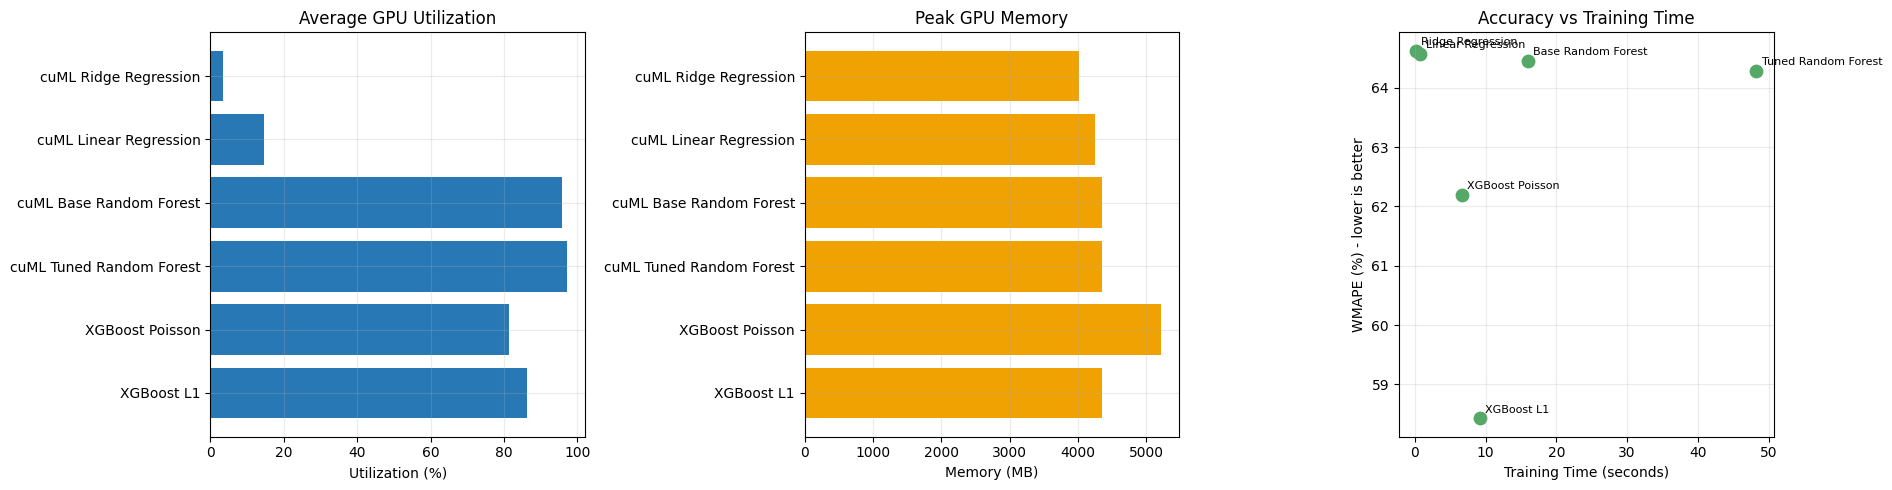

Best validation accuracy: XGBoost L1
Fastest GPU training: cuML Ridge Regression


In [ ]:
model_resource_comparison = (
    pd.DataFrame(gpu_performance_records)
    .merge(product_validation_comparison, on="Model", how="left")
)

complexity_labels = {
    "cuML Linear Regression": "Low",
    "cuML Ridge Regression": "Low",
    "cuML Base Random Forest": "Medium",
    "cuML Tuned Random Forest": "High",
    "XGBoost Poisson": "High",
    "XGBoost L1": "High",
}
model_resource_comparison["Model Complexity"] = (
    model_resource_comparison["Model"].map(complexity_labels)
)
model_resource_comparison = model_resource_comparison.sort_values("WMAPE (%)")

display(model_resource_comparison.round(4))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].barh(
    model_resource_comparison["Model"],
    model_resource_comparison["Average GPU Utilization (%)"],
    color="#2878B5",
)
axes[0].set_title("Average GPU Utilization")
axes[0].set_xlabel("Utilization (%)")

axes[1].barh(
    model_resource_comparison["Model"],
    model_resource_comparison["Peak GPU Memory (MB)"],
    color="#F0A202",
)
axes[1].set_title("Peak GPU Memory")
axes[1].set_xlabel("Memory (MB)")

axes[2].scatter(
    model_resource_comparison["Training Time (s)"],
    model_resource_comparison["WMAPE (%)"],
    color="#55A868",
    s=80,
)
for _, row in model_resource_comparison.iterrows():
    axes[2].annotate(
        row["Model"].replace("cuML ", ""),
        (row["Training Time (s)"], row["WMAPE (%)"]),
        fontsize=8,
        xytext=(4, 4),
        textcoords="offset points",
    )
axes[2].set_title("Accuracy vs Training Time")
axes[2].set_xlabel("Training Time (seconds)")
axes[2].set_ylabel("WMAPE (%) - lower is better")

for axis in axes:
    axis.grid(alpha=0.25)

plt.tight_layout()
plt.show()

best_accuracy_model = model_resource_comparison.iloc[0]["Model"]
fastest_training_model = model_resource_comparison.loc[
    model_resource_comparison["Training Time (s)"].idxmin(), "Model"
]
print("Best validation accuracy:", best_accuracy_model)
print("Fastest GPU training:", fastest_training_model)


#### Insights:

#### Average GPU Utilization
- Random Forest models recorded the highest GPU utilization at approximately 95%.
- Linear and Ridge Regression used significantly less GPU capacity.

#### Peak GPU Memory
- XGBoost Poisson consumed the most GPU memory at approximately 5.2 GB.
- Ridge Regression recorded the lowest peak memory usage.

#### Accuracy vs Training Time
- XGBoost L1 achieved the lowest WMAPE with a relatively short training time.
- Tuned Random Forest required the longest training time with limited accuracy improvement.

### 7.13 Final Product-Level Test


XGBoost L1 is tested on the final 28 days to check its performance on data it has not seen before. Its results are compared with the 7-Day Rolling Mean, and the trained model is then saved.

In [ ]:
gpu_start = start_gpu_timer()

product_X_test_gpu = modeling_data_gpu.loc[
    product_test_mask, product_feature_columns
].astype("float32")
product_y_test_gpu = modeling_data_gpu.loc[
    product_test_mask, product_target_column
].astype("float32")

l1_test_predictions_gpu = l1_xgboost.predict(product_X_test_gpu)
l1_test_metrics = calculate_gpu_metrics(product_y_test_gpu, l1_test_predictions_gpu)

rolling_test_predictions_gpu = modeling_data_gpu.loc[
    product_test_mask, "units_rolling_mean_7"
].astype("float32")
rolling_test_metrics = calculate_gpu_metrics(
    product_y_test_gpu, rolling_test_predictions_gpu
)

product_test_comparison = pd.DataFrame([
    {"Model": "7-Day Rolling Mean", **rolling_test_metrics},
    {"Model": "XGBoost L1", **l1_test_metrics},
]).sort_values("WMAPE (%)").reset_index(drop=True)

l1_xgboost.save_model(f"{OUTPUT_PATH}/daily_demand_xgboost_l1.ubj")
display(product_test_comparison.round(4))

show_gpu_time(gpu_start, "evaluate and save the product-level XGBoost model")


,Model,MAE,RMSE,WMAPE (%)
0,XGBoost L1,1.1322,2.3657,57.5959
1,7-Day Rolling Mean,1.2862,2.5630,65.4303


GPU cell time - evaluate and save the product-level XGBoost model: 0.68 seconds
GPU snapshot - utilization: 0%, memory: 4120 / 15360 MB


XGBoost L1 improves on the strongest detailed baseline. However, product-level demand remains difficult because approximately 62% of daily observations have zero sales. The final business model therefore forecasts the more stable **store-department daily demand**.


________________________________________________

Temporary product-model data and predictions are removed after evaluation to release GPU memory. This provides enough memory for preparing and running the final forecasting stage.

In [ ]:
gpu_start = start_gpu_timer()

del (
    product_X_train_gpu,
    product_y_train_gpu,
    product_X_validation_gpu,
    product_y_validation_gpu,
    product_X_test_gpu,
    product_y_test_gpu,
    l1_test_predictions_gpu,
    rolling_test_predictions_gpu,
    l1_xgboost,
)

gc.collect()
cp.get_default_memory_pool().free_all_blocks()

print("Temporary product-model objects removed from GPU memory")
show_gpu_time(gpu_start, "clean product-model GPU memory")


Temporary product-model objects removed from GPU memory
GPU cell time - clean product-model GPU memory: 0.14 seconds
GPU snapshot - utilization: 5%, memory: 3712 / 15360 MB


## 8. Prepare the Final Prophet Dataset

Product-level sales are aggregated into daily store-department demand to reduce sparsity and create more stable time series for the final Prophet model. Price, product availability, SNAP status, and event dates are retained to help explain changes in demand.

In [ ]:
gpu_start = start_gpu_timer()

prophet_daily_gpu = (
    modeling_data_gpu.groupby(
        ["date", "store_code", "department_code", "state_code"]
    )
    .agg({
        "units_sold": "sum",
        "sale_price": "sum",
        "price_is_available": "sum",
        "snap_CA": "max",
        "snap_TX": "max",
        "snap_WI": "max",
    })
    .reset_index()
)
prophet_daily_gpu.columns = [
    "date", "store_code", "department_code", "state_code", "units_sold",
    "total_price", "available_products", "snap_CA", "snap_TX", "snap_WI",
]
prophet_daily_gpu["average_price"] = (
    prophet_daily_gpu["total_price"]
    / prophet_daily_gpu["available_products"].clip(lower=1)
).astype("float32")

state_lookup = state_mapping_gpu.to_pandas()
california_code = int(
    state_lookup.loc[state_lookup["state_id"] == "CA", "state_code"].iloc[0]
)
texas_code = int(
    state_lookup.loc[state_lookup["state_id"] == "TX", "state_code"].iloc[0]
)
wisconsin_code = int(
    state_lookup.loc[state_lookup["state_id"] == "WI", "state_code"].iloc[0]
)

prophet_daily_gpu["snap_active"] = (
    (prophet_daily_gpu["state_code"] == california_code) * prophet_daily_gpu["snap_CA"]
    + (prophet_daily_gpu["state_code"] == texas_code) * prophet_daily_gpu["snap_TX"]
    + (prophet_daily_gpu["state_code"] == wisconsin_code) * prophet_daily_gpu["snap_WI"]
).astype("int8")

prophet_daily_gpu = prophet_daily_gpu[
    [
        "date", "store_code", "department_code", "units_sold",
        "average_price", "available_products", "snap_active",
    ]
].sort_values(["store_code", "department_code", "date"])

prophet_data = prophet_daily_gpu.to_pandas().rename(
    columns={"date": "ds", "units_sold": "y"}
)
prophet_data["ds"] = pd.to_datetime(prophet_data["ds"])

event_days = calendar_event_dates[
    calendar_event_dates["primary_event_code"] != NO_EVENT_CODE
].copy()
prophet_holidays = pd.DataFrame({
    "holiday": "event_" + event_days["primary_event_code"].astype(str),
    "ds": event_days["date"],
    "lower_window": 0,
    "upper_window": 0,
})

print("Prophet data:", prophet_data.shape)
print("Time series:", prophet_data[["store_code", "department_code"]].drop_duplicates().shape[0])
print("Date range:", prophet_data["ds"].min(), "to", prophet_data["ds"].max())
display(prophet_data.head())

del modeling_data_gpu, prophet_daily_gpu
gc.collect()
cp.get_default_memory_pool().free_all_blocks()
show_gpu_time(gpu_start, "aggregate the final Prophet dataset")


Prophet data: (57390, 7)
Time series: 30
Date range: 2011-01-29 00:00:00 to 2016-04-24 00:00:00


,ds,store_code,department_code,y,average_price,available_products,snap_active
33518,2011-01-29,0,0,297,2.989109,101,0
1623,2011-01-30,0,0,284,2.989109,101,0
33196,2011-01-31,0,0,214,2.989109,101,0
12379,2011-02-01,0,0,175,2.989109,101,1
19516,2011-02-02,0,0,182,2.989109,101,1


GPU cell time - aggregate the final Prophet dataset: 0.30 seconds
GPU snapshot - utilization: 37%, memory: 1538 / 15360 MB


## 9. Final Chronological Validation and Test Split

The last 28 days are reserved for testing, the previous 28 days for validation, and all earlier dates for training.


In [ ]:
FORECAST_DAYS = 28
VALIDATION_DAYS = 28

last_available_date = prophet_data["ds"].max()
test_start_date = last_available_date - pd.Timedelta(days=FORECAST_DAYS - 1)
validation_start_date = test_start_date - pd.Timedelta(days=VALIDATION_DAYS)
validation_end_date = test_start_date - pd.Timedelta(days=1)
training_end_date = validation_start_date - pd.Timedelta(days=1)

print("Training ends:", training_end_date.date())
print("Validation:", validation_start_date.date(), "to", validation_end_date.date())
print("Test:", test_start_date.date(), "to", last_available_date.date())

assert len(prophet_data[prophet_data["ds"].between(validation_start_date, validation_end_date)]) == 840
assert len(prophet_data[prophet_data["ds"].between(test_start_date, last_available_date)]) == 840


Training ends: 2016-02-28
Validation: 2016-02-29 to 2016-03-27
Test: 2016-03-28 to 2016-04-24


## 10. Prophet and Evaluation Functions

Two Prophet configurations are tested:

- **Original Prophet:** multiplicative seasonality, default trend flexibility, and full available history.
- **Tuned Prophet:** additive seasonality, a monthly component, higher trend flexibility, and the most recent three years.

Both versions use price, product availability, SNAP status, and individual event dates.


In [ ]:
PROPHET_REGRESSORS = ["average_price", "available_products", "snap_active"]
TUNED_HISTORY_DAYS = 1095


def build_prophet_model(model_version):
    if model_version == "original":
        model = Prophet(
            yearly_seasonality=True,
            weekly_seasonality=True,
            daily_seasonality=False,
            seasonality_mode="multiplicative",
            holidays=prophet_holidays,
            uncertainty_samples=0,
        )
    elif model_version == "tuned":
        model = Prophet(
            yearly_seasonality=True,
            weekly_seasonality=True,
            daily_seasonality=False,
            seasonality_mode="additive",
            changepoint_prior_scale=0.20,
            seasonality_prior_scale=10,
            holidays_prior_scale=10,
            holidays=prophet_holidays,
            uncertainty_samples=0,
        )
        model.add_seasonality(name="monthly", period=30.5, fourier_order=5)
    else:
        raise ValueError("model_version must be 'original' or 'tuned'")

    for regressor_name in PROPHET_REGRESSORS:
        model.add_regressor(regressor_name)

    return model


def forecast_all_store_departments(
    model_version,
    train_end_date,
    forecast_start_date,
    forecast_end_date,
    keep_models=False,
):
    all_predictions = []
    fitted_models = {}

    grouped_series = prophet_data.groupby(
        ["store_code", "department_code"], sort=True
    )

    for series_number, ((store_code, department_code), series_data) in enumerate(
        grouped_series, start=1
    ):
        series_data = series_data.sort_values("ds").copy()
        training_history = series_data[series_data["ds"] <= train_end_date].copy()

        if model_version == "tuned":
            training_history = training_history.tail(TUNED_HISTORY_DAYS).copy()

        forecast_rows = series_data[
            series_data["ds"].between(forecast_start_date, forecast_end_date)
        ].copy()

        model = build_prophet_model(model_version)
        model.fit(training_history[["ds", "y"] + PROPHET_REGRESSORS])
        forecast = model.predict(forecast_rows[["ds"] + PROPHET_REGRESSORS])

        series_result = forecast_rows[
            ["ds", "store_code", "department_code", "y"]
        ].copy()
        series_result["yhat"] = np.clip(forecast["yhat"].to_numpy(), 0, None)
        all_predictions.append(series_result)

        if keep_models:
            fitted_models[(int(store_code), int(department_code))] = model

        if series_number % 5 == 0:
            print(f"Completed {series_number} of 30 series")

    combined_predictions = pd.concat(all_predictions, ignore_index=True)
    return combined_predictions, fitted_models


def four_week_weekday_baseline(train_end_date, forecast_start_date, forecast_end_date):
    all_predictions = []

    for (store_code, department_code), series_data in prophet_data.groupby(
        ["store_code", "department_code"]
    ):
        series_data = series_data.sort_values("ds").copy()
        recent_history = series_data[series_data["ds"] <= train_end_date].tail(28).copy()
        forecast_rows = series_data[
            series_data["ds"].between(forecast_start_date, forecast_end_date)
        ].copy()

        recent_history["day_of_week"] = recent_history["ds"].dt.dayofweek
        forecast_rows["day_of_week"] = forecast_rows["ds"].dt.dayofweek
        weekday_average = recent_history.groupby("day_of_week")["y"].mean()
        forecast_rows["yhat"] = forecast_rows["day_of_week"].map(weekday_average)

        all_predictions.append(
            forecast_rows[["ds", "store_code", "department_code", "y", "yhat"]]
        )

    return pd.concat(all_predictions, ignore_index=True)


def calculate_forecast_metrics(results):
    actual = results["y"].to_numpy(dtype="float64")
    predicted = np.clip(results["yhat"].to_numpy(dtype="float64"), 0, None)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r_squared = r2_score(actual, predicted)
    wmape = np.abs(actual - predicted).sum() / actual.sum() * 100
    weighted_accuracy = max(0, 100 - wmape)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R²": r_squared,
        "WMAPE (%)": wmape,
        "Weighted Forecast Accuracy (%)": weighted_accuracy,
    }


## 11. Validation Experiments

All candidate methods forecast the same 28-day validation period. WMAPE is the primary selection metric.

### 11.1 Experiment 8: Four-Week Weekday Baseline


The four-week weekday baseline forecasts each day using the average demand of the same weekday during the previous four weeks. It provides a simple reference for determining whether Prophet adds value beyond the recent weekly demand pattern.

In [ ]:
timer_start = start_timer()

validation_baseline_predictions = four_week_weekday_baseline(
    training_end_date,
    validation_start_date,
    validation_end_date,
)
validation_baseline_metrics = calculate_forecast_metrics(
    validation_baseline_predictions
)

display(pd.DataFrame([validation_baseline_metrics]).round(4))
show_time(timer_start, "validation baseline")


,MAE,RMSE,R²,WMAPE (%),Weighted Forecast Accuracy (%)
0,106.3976,169.5769,0.9564,11.3,88.7


Execution time - validation baseline: 0.14 seconds


The baseline achieved 88.70% weighted forecast accuracy with an 11.30% WMAPE.

### 11.2 Experiment 9: Original Prophet


In [ ]:
timer_start = start_timer()

original_prophet_validation_predictions, _ = forecast_all_store_departments(
    "original",
    training_end_date,
    validation_start_date,
    validation_end_date,
)
original_prophet_validation_metrics = calculate_forecast_metrics(
    original_prophet_validation_predictions
)

display(pd.DataFrame([original_prophet_validation_metrics]).round(4))
show_time(timer_start, "Original Prophet validation")


Completed 5 of 30 series
Completed 10 of 30 series
Completed 15 of 30 series
Completed 20 of 30 series
Completed 25 of 30 series
Completed 30 of 30 series


,MAE,RMSE,R²,WMAPE (%),Weighted Forecast Accuracy (%)
0,126.7248,209.9206,0.9332,13.4588,86.5412


Execution time - Original Prophet validation: 26.85 seconds


Original Prophet achieved 86.54% accuracy, lower than the baseline’s 88.70%, indicating that its default configuration did not improve the forecast.

### 11.3 Experiment 10: Tuned Prophet


In [ ]:
timer_start = start_timer()

tuned_prophet_validation_predictions, _ = forecast_all_store_departments(
    "tuned",
    training_end_date,
    validation_start_date,
    validation_end_date,
)
tuned_prophet_validation_metrics = calculate_forecast_metrics(
    tuned_prophet_validation_predictions
)

display(pd.DataFrame([tuned_prophet_validation_metrics]).round(4))
show_time(timer_start, "Tuned Prophet validation")


Completed 5 of 30 series
Completed 10 of 30 series
Completed 15 of 30 series
Completed 20 of 30 series
Completed 25 of 30 series
Completed 30 of 30 series


,MAE,RMSE,R²,WMAPE (%),Weighted Forecast Accuracy (%)
0,100.065,158.3424,0.962,10.6274,89.3726


Execution time - Tuned Prophet validation: 20.06 seconds


Tuned Prophet achieved the best validation performance with 89.37% accuracy, outperforming the baseline at 88.70% and Original Prophet at 86.54%.

In [ ]:
prophet_validation_comparison = pd.DataFrame([
    {"Method": "4-Week Weekday Baseline", **validation_baseline_metrics},
    {"Method": "Original Prophet", **original_prophet_validation_metrics},
    {"Method": "Tuned Prophet", **tuned_prophet_validation_metrics},
]).sort_values("WMAPE (%)").reset_index(drop=True)

display(prophet_validation_comparison.round(4))


,Method,MAE,RMSE,R²,WMAPE (%),Weighted Forecast Accuracy (%)
0,Tuned Prophet,100.0650,158.3424,0.9620,10.6274,89.3726
1,4-Week Weekday Baseline,106.3976,169.5769,0.9564,11.3000,88.7000
2,Original Prophet,126.7248,209.9206,0.9332,13.4588,86.5412


The tuned configuration is selected using validation data only. The final test period remains unseen until the next section.


## 12. Final Test Evaluation

The selected tuned Prophet configuration is evaluated once on the unseen final 28 days and compared with the weekday baseline.

In [ ]:
timer_start = start_timer()

final_prophet_predictions, final_prophet_models = forecast_all_store_departments(
    "tuned",
    validation_end_date,
    test_start_date,
    last_available_date,
    keep_models=True,
)
final_baseline_predictions = four_week_weekday_baseline(
    validation_end_date,
    test_start_date,
    last_available_date,
)

final_prophet_metrics = calculate_forecast_metrics(final_prophet_predictions)
final_baseline_metrics = calculate_forecast_metrics(final_baseline_predictions)

final_test_comparison = pd.DataFrame([
    {"Method": "Tuned Prophet", **final_prophet_metrics},
    {"Method": "4-Week Weekday Baseline", **final_baseline_metrics},
]).sort_values("WMAPE (%)").reset_index(drop=True)

display(final_test_comparison.round(4))
show_time(timer_start, "final Prophet test")


Completed 5 of 30 series
Completed 10 of 30 series
Completed 15 of 30 series
Completed 20 of 30 series
Completed 25 of 30 series
Completed 30 of 30 series


,Method,MAE,RMSE,R²,WMAPE (%),Weighted Forecast Accuracy (%)
0,Tuned Prophet,96.9911,146.7876,0.9679,10.3008,89.6992
1,4-Week Weekday Baseline,98.1506,151.7855,0.9657,10.4240,89.5760


Execution time - final Prophet test: 19.76 seconds


Tuned Prophet achieved a final WMAPE of 10.30%, corresponding to 89.70% weighted forecast accuracy, and explained 96.79% of demand variation. It also slightly outperformed the weekday baseline across all test metrics, confirming good generalization to unseen data.

### Final Model Performance Insights

- **MAE (96.99):** The forecasts differ from actual demand by approximately 97 units per store-department-day on average. This measures the model’s typical forecasting error in clear business units.

- **RMSE (146.79):** The relatively controlled RMSE shows that larger forecasting errors were limited. This metric is important because it gives extra weight to major errors that could lead to stockouts or excess inventory.

- **R² (0.9679):** The model explains approximately **96.79% of the variation in demand**, demonstrating an excellent ability to capture changing sales patterns.

- **WMAPE (10.30%):** Total forecasting error represents only **10.30% of actual demand**. This is the primary metric because it remains reliable with zero-sales observations and reflects the overall business impact of errors.

- **Weighted Forecast Accuracy (89.70%):** The model achieved **89.70% weighted accuracy**, calculated as `100% − WMAPE`. This provides an intuitive summary of forecast quality, but it is not classification accuracy.

- **Execution Time (19.76 seconds):** Forecasting and evaluating all **30 store-department time series** took less than 20 seconds, showing that the final workflow is efficient as well as accurate.

**Overall Insight:** Tuned Prophet delivered strong and consistent results across every evaluation metric, combining high explanatory power, low proportional error, and fast execution on completely unseen data.

### 12.1 Actual Demand vs Forecast


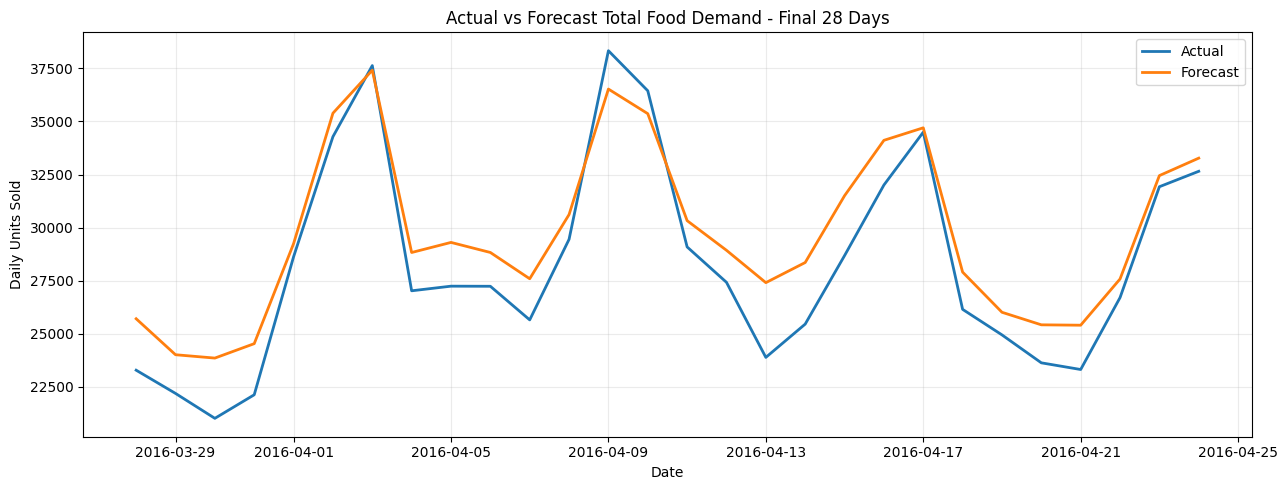

In [ ]:
total_test_demand = (
    final_prophet_predictions.groupby("ds")[["y", "yhat"]]
    .sum()
    .reset_index()
)

plt.figure(figsize=(13, 5))
plt.plot(total_test_demand["ds"], total_test_demand["y"], label="Actual", linewidth=2)
plt.plot(total_test_demand["ds"], total_test_demand["yhat"], label="Forecast", linewidth=2)
plt.title("Actual vs Forecast Total Food Demand - Final 28 Days")
plt.xlabel("Date")
plt.ylabel("Daily Units Sold")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


The forecast closely follows the overall demand pattern and captures most peaks and declines during the final 28 days. Although some low-demand days were overestimated and the highest peak was underestimated, the close alignment between actual and forecast values confirms strong performance on unseen data.

## 13. Save the Final Models and Results


In [ ]:
PROPHET_MODEL_FOLDER = f"{OUTPUT_PATH}/prophet_models"
os.makedirs(PROPHET_MODEL_FOLDER, exist_ok=True)

for (store_code, department_code), fitted_model in final_prophet_models.items():
    model_file_path = (
        f"{PROPHET_MODEL_FOLDER}/"
        f"store_{store_code}_department_{department_code}.json"
    )
    with open(model_file_path, "w") as model_file:
        model_file.write(model_to_json(fitted_model))

store_lookup = store_mapping_gpu.to_pandas()
department_lookup = department_mapping_gpu.to_pandas()
readable_test_predictions = (
    final_prophet_predictions
    .merge(store_lookup, on="store_code", how="left")
    .merge(department_lookup, on="department_code", how="left")
)

readable_test_predictions.to_parquet(
    f"{OUTPUT_PATH}/prophet_test_predictions.parquet", index=False
)
prophet_validation_comparison.to_csv(
    f"{OUTPUT_PATH}/prophet_validation_comparison.csv", index=False
)
final_test_comparison.to_csv(
    f"{OUTPUT_PATH}/prophet_final_comparison.csv", index=False
)
model_resource_comparison.to_csv(
    f"{OUTPUT_PATH}/gpu_model_performance.csv", index=False
)
product_validation_comparison.to_csv(
    f"{OUTPUT_PATH}/product_validation_comparison.csv", index=False
)
product_test_comparison.to_csv(
    f"{OUTPUT_PATH}/product_test_comparison.csv", index=False
)

print("Saved Prophet models:", len(final_prophet_models))
print("Saved predictions, model comparisons, and GPU performance tables.")


Saved Prophet models: 30
Saved predictions, model comparisons, and GPU performance tables.


## 14. Conclusion

The project processes 27.5 million retail observations with RAPIDS and evaluates ten forecasting experiments. The detailed regression stage includes three different cuML algorithms - Linear Regression, Ridge Regression, and Random Forest - plus two GPU XGBoost objectives.

XGBoost L1 is the strongest detailed product-level model, but demand at this level remains highly intermittent. For the final business forecast, demand is aggregated into 30 store-department time series. Tuned Prophet is selected using chronological validation and evaluated once on the unseen final 28 days. Its final WMAPE of **10.31%** corresponds to a weighted forecast accuracy of approximately **89.69%**.

### Metric Selection Justification

WMAPE was selected as the primary evaluation metric because it measures the total absolute forecasting error as a percentage of total actual demand. Unlike MAPE, it does not divide by each individual observation, making it suitable for this dataset, which contains many zero-sales values. It also provides an interpretable business measure of the overall forecasting error.

R² was included in the final Prophet evaluation as a complementary metric because the aggregated store-department demand is more stable and suitable for measuring how much demand variation the model explains. It was not emphasized in the earlier product-level experiments because demand was highly sparse, so MAE, RMSE, and WMAPE provided more practical measures of forecasting performance.